# Indian Fake-Currency Detection with Explainable AIA complete, runnable pipeline in one notebook:| Stage | What it does ||---|---|| 1 | Upload an image **or capture one from the webcam** || 2 | **Image-quality gate** — blur / brightness / glare / resolution || 3 | Preprocessing — deskew, perspective-warp, CLAHE, colour spaces || 4 | **Denomination detection** — 6-class CNN (₹10, ₹20, ₹50, ₹100, ₹200, ₹500) + confidence || 5 | **Genuine vs Counterfeit** — dedicated binary CNN + confidence || 6 | **Security-feature analysis** — watermark, security thread, bleed lines / micro-lettering, latent image, see-through register || 7 | **Suspicious-region localisation** — bounding boxes over whichever features failed || 8 | **Grad-CAM** — heatmap of what the network actually looked at || 9 | **Overall review** — risk score, confidence, score breakdown || 10 | **Audible alarm** if the note is counterfeit || 11 | **Explainable-AI report** — what note it is, genuine or not, and *why*; downloadable HTML |### How to run`Runtime ▸ Run all`, then follow the prompts in §1 (models) and §3 (image).> **Models:** §1 lets you upload your trained `denomination_cnn.keras` and> `authentication_cnn_clean.keras`. If you don't have them, §1b trains both from a dataset> folder. Everything downstream is identical either way.

---## 0 · Environment setupWe force **Keras 2** via `tf_keras`, because the `.keras` files from the original project weresaved with Keras 2 and fail to load under Colab's default Keras 3. The environment variable hasto be set *before* TensorFlow is imported, so run this cell first and don't re-order it.

In [2]:

import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import cv2
import base64
import json
import datetime
import re
import glob
import io
import sys
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import HTML, Audio, display, Javascript

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

DENOM_MODEL_PATH = "models/denomination_cnn.keras"
AUTH_MODEL_PATH = "models/authentication_cnn_clean.keras"

print("Project setup completed successfully!")


TensorFlow: 2.15.1
OpenCV: 4.11.0
Project setup completed successfully!


In [3]:
import os

os.makedirs("models", exist_ok=True)

print("Models folder contents:")
print(os.listdir("models"))


Models folder contents:
['authentication_cnn_clean.keras', 'denomination_cnn.keras']


---## 1 · Provide the trained models**Option A (fast, recommended).** Run the cell below and upload the two files from your project's`models/` folder:* `denomination_cnn.keras` — 6-class denomination CNN* `authentication_cnn_clean.keras` — binary genuine/counterfeit CNNA `.zip` containing them also works. Then skip straight to §1c.**Option B.** Skip this cell and train from scratch in §1b.

In [5]:
import os

print("Pre-trained models available:")

for f in sorted(os.listdir("models")):
    if f.endswith((".keras", ".h5")):
        size = os.path.getsize(os.path.join("models", f)) / 1e6
        print(f"{f} ({size:.1f} MB)")

print("\nBoth pre-trained models are ready!")

Pre-trained models available:
authentication_cnn_clean.keras (5.1 MB)
denomination_cnn.keras (5.2 MB)

Both pre-trained models are ready!


---## 1b · (Optional) Train both models from a dataset folderOnly needed if you did **not** upload models above.Point `DATASET_DIR` at a folder in either of these layouts:```data/real/10/*.jpg   data/fake/10/*.jpg      # lowercase real/fakedata/Real/10/*.jpg   data/Fake/10/*.jpg      # or capitalised — both work```A ready-made source is the Kaggle *Indian currency notes (real/fake)* dataset; mount Drive or`!unzip` it into the runtime first. The bundled `sample_dataset/` from your project also works,but with only 3 images per class the resulting models are a wiring demo, not a usable detector —the cell warns you when the dataset is that small.`SKIP_TRAINING` is set automatically when both models already exist, so *Run all* is safe.

In [6]:
def _load(path, label):
    if not os.path.exists(path):
        print("MISSING %s: %s" % (label, path))
        return None

    try:
        m = tf.keras.models.load_model(path, compile=False)
        print("Loaded %s: in=%s out=%s" % (label, m.input_shape, m.output_shape))
        return m
    except Exception as e:
        print("FAILED %s: %s" % (label, e))
        return None


print("===== MODEL LOADING =====")

denomination_model = _load(
    DENOM_MODEL_PATH,
    "denomination CNN"
)

authentication_model = _load(
    AUTH_MODEL_PATH,
    "authentication CNN"
)

assert denomination_model is not None, \
    "Denomination model unavailable — see 1 / 1b."

assert authentication_model is not None, \
    "Authentication model unavailable — see 1 / 1b."

assert denomination_model.output_shape[-1] == 6, \
    "Denomination model must output 6 classes, got %s" % (
        denomination_model.output_shape
    )

assert authentication_model.output_shape[-1] == 1, \
    "Authentication model must output 1 sigmoid unit, got %s" % (
        authentication_model.output_shape
    )

print("\nBoth models loaded and shape-checked.")

===== MODEL LOADING =====


Loaded denomination CNN: in=(None, 128, 128, 3) out=(None, 6)
Loaded authentication CNN: in=(None, 128, 128, 3) out=(None, 1)

Both models loaded and shape-checked.


---## 1c · Load the modelsThis also asserts the output-shape contract the rest of the notebook depends on: 6 softmaxclasses for the denomination net, 1 sigmoid unit for the authentication net.

---## 2 · The pipelineThe next five cells define every stage. They are a direct port of the project's `pipeline/`package, with three bugs fixed along the way:* `anomaly_localization` passed `cv2.COLORMAP_JET` where `cv2.putText` expects a **font**, so the  region labels never drew. Now uses `FONT_HERSHEY_SIMPLEX`.* `risk_scorer` tested `failed_features >= 2` before `>= 3`, making the `>= 3` branch dead code.  The checks now run high-to-low.* Grad-CAM divided by the heatmap maximum without checking it was positive, producing NaNs when  no gradient was positive. It now falls back to the saliency map in that case.

### 2a · Stages 2–3 — quality gate and preprocessing

In [8]:
# =============================================================================
# STAGE 2 - IMAGE QUALITY & VISIBILITY CHECK
# =============================================================================

def check_image_quality(
    image,
    min_blur_thresh=80.0,
    max_glare_ratio=0.15,
    min_resolution=(100, 100)
):
    """Check whether the image is clear enough to analyse."""

    if image is None or image.size == 0:
        return {
            "passed": False,
            "quality_score": 0.0,
            "blur_variance": 0.0,
            "brightness_mean": 0.0,
            "glare_ratio": 1.0,
            "resolution": (0, 0),
            "warnings": ["Invalid or unreadable image file."]
        }

    h, w = image.shape[:2]
    warnings = []

    if h < min_resolution[0] or w < min_resolution[1]:
        warnings.append(
            "Low resolution (%dx%dpx)." % (w, h)
        )

    gray = (
        cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        if image.ndim == 3
        else image.copy()
    )

    laplacian_var = float(
        cv2.Laplacian(gray, cv2.CV_64F).var()
    )

    if laplacian_var < min_blur_thresh:
        warnings.append(
            "Image is blurry (blur score %.1f)." % laplacian_var
        )

    brightness_mean = float(np.mean(gray))

    if brightness_mean < 45.0:
        warnings.append("Image is too dark.")

    elif brightness_mean > 230.0:
        warnings.append("Image is overexposed.")

    glare_ratio = float(
        np.sum(gray >= 250) / (w * h)
    )

    if glare_ratio > max_glare_ratio:
        warnings.append(
            "High glare (%.1f%%)." % (glare_ratio * 100)
        )

    blur_component = (
        min(1.0, laplacian_var / 300.0) * 40
    )

    bright_component = (
        max(
            0.0,
            1.0 - abs(brightness_mean - 128) / 128.0
        ) * 30
    )

    glare_component = (
        max(
            0.0,
            1.0 - glare_ratio / max_glare_ratio
        ) * 30
    )

    quality_score = float(
        round(
            blur_component
            + bright_component
            + glare_component,
            2
        )
    )

    passed = (
        (not warnings)
        or (
            quality_score >= 50.0
            and laplacian_var >= min_blur_thresh / 2
        )
    )

    return {
        "passed": passed,
        "quality_score": quality_score,
        "blur_variance": round(laplacian_var, 2),
        "brightness_mean": round(brightness_mean, 2),
        "glare_ratio": round(glare_ratio, 4),
        "resolution": (w, h),
        "warnings": warnings
    }


# =============================================================================
# STAGE 3 - PREPROCESSING
# =============================================================================

def to_base64_img(img_bgr):

    if img_bgr is None or img_bgr.size == 0:
        return ""

    _, buf = cv2.imencode(".jpg", img_bgr)

    return (
        "data:image/jpeg;base64,"
        + base64.b64encode(buf).decode("utf-8")
    )


def order_points(pts):
    """Order four corners."""

    rect = np.zeros((4, 2), dtype="float32")

    s = pts.sum(axis=1)

    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]

    d = np.diff(pts, axis=1)

    rect[1] = pts[np.argmin(d)]
    rect[3] = pts[np.argmax(d)]

    return rect


def align_banknote(image):
    """Find and straighten the banknote."""

    h, w = image.shape[:2]

    if h > w:
        image = cv2.rotate(
            image,
            cv2.ROTATE_90_CLOCKWISE
        )

    gray = (
        cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        if image.ndim == 3
        else image.copy()
    )

    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    edged = cv2.Canny(
        blurred,
        50,
        200
    )

    contours, _ = cv2.findContours(
        edged.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return image, False

    card = None

    for c in sorted(
        contours,
        key=cv2.contourArea,
        reverse=True
    )[:5]:

        approx = cv2.approxPolyDP(
            c,
            0.02 * cv2.arcLength(c, True),
            True
        )

        if (
            len(approx) == 4
            and cv2.contourArea(c)
            > image.shape[0] * image.shape[1] * 0.15
        ):
            card = approx
            break

    if card is None:
        return image, False

    rect = order_points(
        card.reshape(4, 2)
    )

    tl, tr, br, bl = rect

    maxW = max(
        int(np.linalg.norm(br - bl)),
        int(np.linalg.norm(tr - tl))
    )

    maxH = max(
        int(np.linalg.norm(tr - br)),
        int(np.linalg.norm(tl - bl))
    )

    if maxW < 10 or maxH < 10:
        return image, False

    dst = np.array(
        [
            [0, 0],
            [maxW - 1, 0],
            [maxW - 1, maxH - 1],
            [0, maxH - 1]
        ],
        dtype="float32"
    )

    matrix = cv2.getPerspectiveTransform(
        rect,
        dst
    )

    warped = cv2.warpPerspective(
        image,
        matrix,
        (maxW, maxH)
    )

    if warped.shape[0] > warped.shape[1]:
        warped = cv2.rotate(
            warped,
            cv2.ROTATE_90_CLOCKWISE
        )

    return warped, True


def preprocess_banknote(
    image,
    target_size=(256, 128)
):
    """Prepare the currency image for the models."""

    if image is None or image.size == 0:
        raise ValueError(
            "Empty image passed to preprocessing."
        )

    # Denomination model input
    denomination_rgb = cv2.resize(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        ),
        (128, 128)
    )

    denomination_rgb = (
        denomination_rgb.astype(np.float32) / 255.0
    )

    # Align banknote
    aligned_img, aligned_success = align_banknote(
        image
    )

    resized_bgr = cv2.resize(
        aligned_img,
        target_size
    )

    denoised_bgr = cv2.bilateralFilter(
        resized_bgr,
        d=7,
        sigmaColor=50,
        sigmaSpace=50
    )

    rgb = cv2.cvtColor(
        denoised_bgr,
        cv2.COLOR_BGR2RGB
    )

    gray = cv2.cvtColor(
        denoised_bgr,
        cv2.COLOR_BGR2GRAY
    )

    hsv = cv2.cvtColor(
        denoised_bgr,
        cv2.COLOR_BGR2HSV
    )

    lab = cv2.cvtColor(
        denoised_bgr,
        cv2.COLOR_BGR2LAB
    )

    clahe_gray = cv2.createCLAHE(
        clipLimit=2.5,
        tileGridSize=(8, 8)
    ).apply(gray)

    return {
        "denomination_rgb": denomination_rgb,
        "aligned_success": aligned_success,
        "original": image,
        "aligned": aligned_img,
        "resized_bgr": resized_bgr,
        "denoised_bgr": denoised_bgr,
        "rgb": rgb,
        "gray": gray,
        "clahe_gray": clahe_gray,
        "hsv": hsv,
        "lab": lab,
        "normalized_rgb": (
            rgb.astype("float32") / 255.0
        ),
        "target_size": target_size,
        "original_b64": to_base64_img(image),
        "aligned_b64": to_base64_img(aligned_img),
        "clahe_b64": to_base64_img(
            cv2.cvtColor(
                clahe_gray,
                cv2.COLOR_GRAY2BGR
            )
        ),
        "denoised_b64": to_base64_img(
            denoised_bgr
        )
    }


print("Stages 2-3 defined.")

Stages 2-3 defined.


### 2b · Stages 4–5 — denomination and genuine/counterfeit

In [9]:
# =============================================================================
# STAGE 4 - DENOMINATION CLASSIFICATION
# =============================================================================

DENOMINATIONS_INFO = {
    "10": {
        "name": "Rs.10 (Ten Rupee)",
        "color_name": "Chocolate Brown",
        "hsv_range": ((5, 50, 50), (25, 255, 255))
    },
    "20": {
        "name": "Rs.20 (Twenty Rupee)",
        "color_name": "Greenish Yellow",
        "hsv_range": ((20, 50, 50), (40, 255, 255))
    },
    "50": {
        "name": "Rs.50 (Fifty Rupee)",
        "color_name": "Fluorescent Blue",
        "hsv_range": ((85, 50, 50), (115, 255, 255))
    },
    "100": {
        "name": "Rs.100 (One Hundred Rupee)",
        "color_name": "Lavender",
        "hsv_range": ((120, 30, 50), (150, 255, 255))
    },
    "200": {
        "name": "Rs.200 (Two Hundred Rupee)",
        "color_name": "Bright Yellow",
        "hsv_range": ((22, 100, 100), (35, 255, 255))
    },
    "500": {
        "name": "Rs.500 (Five Hundred Rupee)",
        "color_name": "Stone Grey",
        "hsv_range": ((0, 0, 40), (180, 40, 200))
    }
}

MODEL_CLASSES = ["10", "20", "50", "100", "200", "500"]


def classify_denomination(prep, model=None):

    rgb = prep.get("denomination_rgb")

    if rgb is None:
        rgb = prep.get("rgb")

    if rgb is None:
        raise ValueError("Denomination RGB image is missing.")

    if model is not None:

        try:

            th = model.input_shape[1] or 128
            tw = model.input_shape[2] or 128

            inp = np.expand_dims(
                cv2.resize(rgb, (tw, th)).astype(np.float32),
                0
            )

            preds = model.predict(
                inp,
                verbose=0
            )[0]

            if len(preds) != 6:
                raise ValueError(
                    "Expected 6 classes, model returned %d"
                    % len(preds)
                )

            top = int(np.argmax(preds))

            code_ = MODEL_CLASSES[top]
            info = DENOMINATIONS_INFO[code_]

            return {
                "code": code_,
                "denomination": info["name"],
                "confidence": round(
                    float(preds[top]) * 100,
                    2
                ),
                "color_profile": info["color_name"],
                "all_probabilities": {
                    "Rs." + MODEL_CLASSES[i]:
                    round(float(preds[i]) * 100, 2)
                    for i in range(6)
                },
                "model_used":
                    "Dedicated 6-class denomination CNN"
            }

        except Exception as e:

            print(
                "WARNING: denomination CNN failed:",
                e
            )

    hsv = prep.get("hsv")

    if hsv is None:
        raise ValueError(
            "HSV image missing; cannot run denomination fallback."
        )

    total = hsv.shape[0] * hsv.shape[1]

    scores = {}

    for c, info in DENOMINATIONS_INFO.items():

        mask = cv2.inRange(
            hsv,
            np.array(info["hsv_range"][0]),
            np.array(info["hsv_range"][1])
        )

        scores[c] = float(
            np.sum(mask > 0) / total
        )

    best = max(
        scores,
        key=scores.get
    )

    info = DENOMINATIONS_INFO[best]

    conf = min(
        98.5,
        max(
            65.0,
            scores[best] * 300.0 + 60.0
        )
    )

    return {
        "code": best,
        "denomination": info["name"],
        "confidence": round(conf, 2),
        "color_profile": info["color_name"],
        "all_probabilities": {},
        "scores": scores,
        "model_used": "HSV colour fallback"
    }


# =============================================================================
# STAGE 5 - GENUINE / COUNTERFEIT AUTHENTICATION
# =============================================================================

def analyze_intaglio_microstructure(clahe_gray):

    lap = float(
        cv2.Laplacian(
            clahe_gray,
            cv2.CV_64F
        ).var()
    )

    sx = cv2.Sobel(
        clahe_gray,
        cv2.CV_64F,
        1,
        0,
        ksize=3
    )

    sy = cv2.Sobel(
        clahe_gray,
        cv2.CV_64F,
        0,
        1,
        ksize=3
    )

    edge_energy = float(
        np.mean(
            np.square(sx) + np.square(sy)
        )
    )

    hf = min(
        1.0,
        (lap * 0.35 + edge_energy * 0.65) / 2200.0
    )

    return {
        "laplacian_var": round(lap, 2),
        "edge_energy": round(edge_energy, 2),
        "intaglio_score": round(hf * 100, 1),
        "is_flat_print": bool(
            hf * 100 < 25.0
        )
    }


def authenticate_note(prep, model=None):

    rgb = prep.get("rgb")
    clahe_gray = prep.get("clahe_gray")

    if rgb is None:
        raise ValueError(
            "Preprocessed RGB image is missing."
        )

    if model is None:
        raise ValueError(
            "Authentication model is not loaded."
        )

    h = model.input_shape[1] or 128
    w = model.input_shape[2] or 128

    inp = np.expand_dims(
        cv2.resize(rgb, (w, h)).astype(np.float32) / 255.0,
        0
    )

    preds = model.predict(
        inp,
        verbose=0
    )

    fake_prob = max(
        0.0,
        min(
            1.0,
            float(np.squeeze(preds))
        )
    )

    real_prob = 1.0 - fake_prob

    is_real = real_prob >= 0.50

    if clahe_gray is not None:

        intaglio = analyze_intaglio_microstructure(
            clahe_gray
        )

    else:

        intaglio = {
            "laplacian_var": 0.0,
            "edge_energy": 0.0,
            "intaglio_score": 0.0,
            "is_flat_print": False
        }

    return {
        "is_real": bool(is_real),
        "status":
            "GENUINE" if is_real else "COUNTERFEIT",
        "real_probability":
            round(real_prob * 100, 2),
        "fake_probability":
            round(fake_prob * 100, 2),
        "model_used":
            "Dedicated authentication CNN",
        "intaglio": intaglio
    }


print("Stages 4-5 defined.")

Stages 4-5 defined.


### 2b-2 · Stage 5b — novelty / play-money text checkToy notes, film props and "Children Bank of India" notes are the most common fakes actuallypassed in India, and they are trivially identifiable: they *say so on the note*. They carry textlike `CHILDREN BANK OF INDIA`, `BHARATIYA MANORANJAN BANK` or `PLAY MONEY` where a genuine notereads `RESERVE BANK OF INDIA`.No CNN is needed for this and none should be trusted with it — a denomination model has no"not a banknote" class, so it will confidently label a toy note `₹500`. Reading the text is bothmore reliable and more explainable, so a positive match here **hard-overrides** every otherstage: verdict counterfeit, risk 99, alarm on.

In [10]:
# =============================================================================
# STAGE 5b - NOVELTY / PLAY-MONEY TEXT DETECTION
# =============================================================================

NOVELTY_PHRASES = [
    "children bank",
    "childrens bank",
    "children s bank",
    "child bank",
    "bharatiya manoranjan",
    "manoranjan bank",
    "manoranjan",
    "play money",
    "playmoney",
    "toy money",
    "money for play",
    "not legal tender",
    "for educational purpose",
    "educational purpose",
    "for film purpose",
    "film shooting",
    "movie prop",
    "prop money",
    "specimen",
    "sample only",
    "facsimile",
    "replica",
    "novelty"
]

GENUINE_PHRASES = [
    "reserve bank of india",
    "reserve bank",
    "bhartiya reserve",
    "भारतीय रिज़र्व बैंक"
]


def _ocr_variants(prep):
    """Create multiple image versions for OCR."""

    variants = []

    gray = prep["clahe_gray"]

    big = cv2.resize(
        gray,
        None,
        fx=3.0,
        fy=3.0,
        interpolation=cv2.INTER_CUBIC
    )

    variants.append(big)

    binary = cv2.threshold(
        big,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )[1]

    variants.append(binary)

    inverse = cv2.threshold(
        big,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )[1]

    variants.append(inverse)

    return variants


def detect_novelty_note(prep):
    """Detect novelty/play-money text using OCR."""

    try:
        import pytesseract

    except Exception as e:

        return {
            "available": False,
            "is_novelty": False,
            "matched_phrases": [],
            "rbi_text_found": None,
            "ocr_text": "",
            "note":
                "OCR not installed (%s) - novelty check skipped."
                % e
        }

    text_parts = []

    try:

        for v in _ocr_variants(prep):

            for psm in ("--psm 6", "--psm 11"):

                text = pytesseract.image_to_string(
                    v,
                    config=psm
                )

                if text:
                    text_parts.append(text)

        text = " ".join(text_parts).lower()

        matched = []

        for phrase in NOVELTY_PHRASES:

            if phrase.lower() in text:
                matched.append(phrase)

        rbi_found = any(
            phrase.lower() in text
            for phrase in GENUINE_PHRASES
        )

        return {
            "available": True,
            "is_novelty": len(matched) > 0,
            "matched_phrases": matched,
            "rbi_text_found": rbi_found,
            "ocr_text": text[:3000],
            "note":
                "Novelty wording detected."
                if matched
                else "No novelty wording detected by OCR."
        }

    except Exception as e:

        return {
            "available": True,
            "is_novelty": False,
            "matched_phrases": [],
            "rbi_text_found": None,
            "ocr_text": "",
            "note":
                "OCR processing failed: %s" % e
        }


print("Stage 5b defined.")

Stage 5b defined.


### 2c · Stages 6–7 — security features and suspicious-region localisation

In [13]:
# =============================================================================
# STAGE 6 - SECURITY-FEATURE VERIFICATION
# =============================================================================

ROI_DEFINITIONS = {
    "watermark": {
        "name": "Mahatma Gandhi Watermark",
        "coords": (0.15, 0.85, 0.05, 0.32),
        "description": "Multi-tonal paper portrait watermark"
    },
    "security_thread": {
        "name": "Windowed Security Thread",
        "coords": (0.05, 0.95, 0.42, 0.50),
        "description": "Vertical metallic security thread"
    },
    "bleed_lines": {
        "name": "Bleed Lines and Micro-lettering",
        "coords": (0.10, 0.90, 0.01, 0.08),
        "description": "Tactile bleed lines and micro-lettering"
    },
    "latent_image": {
        "name": "Latent Image and Numeral",
        "coords": (0.60, 0.95, 0.70, 0.95),
        "description": "Denomination numeral latent image"
    },
    "see_through": {
        "name": "See-Through Register",
        "coords": (0.15, 0.45, 0.30, 0.42),
        "description": "Overlapping see-through register"
    }
}


def verify_security_features(prep, denomination_code="500"):

    resized_bgr = prep["resized_bgr"]
    clahe_gray = prep["clahe_gray"]
    hsv = prep["hsv"]

    H, W = resized_bgr.shape[:2]

    results = {}
    passed_count = 0

    for key, spec in ROI_DEFINITIONS.items():

        y1, y2, x1, x2 = spec["coords"]

        ymin = int(y1 * H)
        ymax = int(y2 * H)

        xmin = int(x1 * W)
        xmax = int(x2 * W)

        crop_bgr = resized_bgr[ymin:ymax, xmin:xmax]
        crop_gray = clahe_gray[ymin:ymax, xmin:xmax]
        crop_hsv = hsv[ymin:ymax, xmin:xmax]

        score = 0.0
        details = ""

        metric = ""
        expected = ""
        observed = ""
        difference = ""

        # ---------------------------------------------------------
        # WATERMARK
        # ---------------------------------------------------------

        if key == "watermark":

            edges = cv2.Canny(
                crop_gray,
                60,
                180
            )

            edge_density = float(
                np.sum(edges > 0) / edges.size
            )

            std_dev = float(
                np.std(crop_gray)
            )

            metric = "Tonal spread and edge density"

            expected = (
                "Tonal spread 10-55 with edge density under 18%"
            )

            observed = (
                "tonal spread %.1f, edge density %.1f%%"
                % (std_dev, edge_density * 100)
            )

            if (
                10.0 <= std_dev <= 55.0
                and edge_density < 0.18
            ):

                score = min(
                    100.0,
                    max(
                        55.0,
                        (1.0 - edge_density * 3.5) * 90.0
                    )
                )

                details = (
                    "Smooth watermark gradient present (%s)"
                    % observed
                )

            else:

                score = max(
                    10.0,
                    40.0 - edge_density * 200.0
                )

                details = (
                    "Watermark pattern appears suspicious (%s)"
                    % observed
                )

                difference = (
                    "The observed tonal/edge pattern differs "
                    "from the expected smooth watermark pattern."
                )

        # ---------------------------------------------------------
        # SECURITY THREAD
        # ---------------------------------------------------------

        elif key == "security_thread":

            sx = np.abs(
                cv2.Sobel(
                    crop_gray,
                    cv2.CV_64F,
                    1,
                    0,
                    ksize=3
                )
            )

            sy = np.abs(
                cv2.Sobel(
                    crop_gray,
                    cv2.CV_64F,
                    0,
                    1,
                    ksize=3
                )
            )

            vert_mean = float(
                np.mean(sx)
            )

            vert_ratio = (
                vert_mean /
                (float(np.mean(sy)) + 1e-5)
            )

            hue_std = float(
                np.std(crop_hsv[:, :, 0])
            )

            metric = (
                "Vertical-to-horizontal gradient ratio"
            )

            expected = (
                "Ratio above 1.2 or mean vertical gradient above 45"
            )

            observed = (
                "ratio %.2f, gradient %.1f, hue spread %.1f"
                % (
                    vert_ratio,
                    vert_mean,
                    hue_std
                )
            )

            if (
                vert_ratio > 1.2
                or vert_mean > 45.0
            ):

                score = min(
                    100.0,
                    max(
                        55.0,
                        vert_ratio * 35.0
                        + hue_std * 0.7
                    )
                )

                details = (
                    "Metallic thread structure detected (%s)"
                    % observed
                )

            else:

                score = max(
                    15.0,
                    min(
                        40.0,
                        vert_ratio * 20.0
                    )
                )

                details = (
                    "Security thread structure not clearly detected (%s)"
                    % observed
                )

                difference = (
                    "The observed directional gradient is below "
                    "the expected security-thread pattern."
                )

        # ---------------------------------------------------------
        # BLEED LINES
        # ---------------------------------------------------------

        elif key == "bleed_lines":

            line_density = float(
                np.mean(
                    np.abs(
                        cv2.Sobel(
                            crop_gray,
                            cv2.CV_64F,
                            1,
                            0,
                            ksize=3
                        )
                    )
                )
            )

            metric = "Line density"

            expected = "Above 20"

            observed = "%.1f" % line_density

            if line_density > 20.0:

                score = min(
                    100.0,
                    line_density * 1.8
                )

                details = (
                    "Bleed-line density %.1f"
                    % line_density
                )

            else:

                score = max(
                    15.0,
                    line_density * 0.8
                )

                details = (
                    "Micro-lettering appears faint or absent"
                )

                difference = (
                    "Observed line density %.1f is below "
                    "the expected value above 20."
                    % line_density
                )

        # ---------------------------------------------------------
        # LATENT IMAGE
        # ---------------------------------------------------------

        elif key == "latent_image":

            lap = float(
                cv2.Laplacian(
                    crop_gray,
                    cv2.CV_64F
                ).var()
            )

            metric = "Texture variance"

            expected = "Above 60"

            observed = "%.1f" % lap

            if lap > 60.0:

                score = min(
                    100.0,
                    max(
                        50.0,
                        lap * 0.35
                    )
                )

                details = (
                    "Latent-image texture variance %.1f"
                    % lap
                )

            else:

                score = max(
                    20.0,
                    lap * 0.15
                )

                details = (
                    "Latent-image region appears flat"
                )

                difference = (
                    "Texture variance %.1f is below "
                    "the expected value above 60."
                    % lap
                )

        # ---------------------------------------------------------
        # SEE-THROUGH REGISTER
        # ---------------------------------------------------------

        elif key == "see_through":

            edges = cv2.Canny(
                crop_gray,
                50,
                150
            )

            edge_ratio = float(
                np.sum(edges > 0) / edges.size
            )

            metric = "Register print density"

            expected = "At least 0.5%"

            observed = "%.2f%%" % (
                edge_ratio * 100
            )

            if edge_ratio >= 0.005:

                score = min(
                    100.0,
                    max(
                        50.0,
                        edge_ratio * 450.0
                    )
                )

                details = (
                    "Register print density %.2f%%"
                    % (edge_ratio * 100)
                )

            else:

                score = 30.0

                details = (
                    "Low see-through register density"
                )

                difference = (
                    "Observed register density %.2f%% "
                    "is below the expected 0.5%%."
                    % (edge_ratio * 100)
                )

        score = round(
            float(score),
            1
        )

        passed = score >= 45.0

        passed_count += int(passed)

        results[key] = {
            "name": spec["name"],
            "description": spec["description"],
            "score": score,
            "passed": passed,
            "status":
                "Verified"
                if passed
                else "Suspicious / Missing",
            "details": details,
            "metric": metric,
            "expected": expected,
            "observed": observed,
            "difference": difference,
            "bbox": [
                xmin,
                ymin,
                xmax - xmin,
                ymax - ymin
            ],
            "crop_base64":
                to_base64_img(crop_bgr)
        }

    total = len(ROI_DEFINITIONS)

    return {
        "pass_ratio":
            round(
                passed_count / total * 100,
                1
            ),
        "passed_features":
            passed_count,
        "total_features":
            total,
        "feature_details":
            results
    }


# =============================================================================
# STAGE 7 - SUSPICIOUS-REGION LOCALISATION
# =============================================================================

def localize_suspicious_regions(
    prep,
    security_results
):

    annotated = prep["resized_bgr"].copy()

    clahe_gray = prep["clahe_gray"]

    H, W = annotated.shape[:2]

    suspicious = []

    # Failed security features
    for feat in security_results.get(
        "feature_details",
        {}
    ).values():

        if feat["passed"]:
            continue

        xmin, ymin, w, h = feat["bbox"]

        severity = (
            "HIGH"
            if feat["score"] < 40.0
            else "MEDIUM"
        )

        suspicious.append({
            "feature": feat["name"],
            "reason":
                "Failed verification (score %s%%)"
                % feat["score"],
            "bbox": [
                xmin,
                ymin,
                w,
                h
            ],
            "severity": severity
        })

        colour = (
            (0, 0, 255)
            if severity == "HIGH"
            else (0, 140, 255)
        )

        cv2.rectangle(
            annotated,
            (xmin, ymin),
            (xmin + w, ymin + h),
            colour,
            2
        )

        cv2.putText(
            annotated,
            feat["name"][:20],
            (xmin, max(11, ymin - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.30,
            colour,
            1,
            cv2.LINE_AA
        )

    # Texture residual
    diff = cv2.absdiff(
        clahe_gray,
        cv2.GaussianBlur(
            clahe_gray,
            (15, 15),
            0
        )
    )

    norm_diff = cv2.normalize(
        diff,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    heatmap_colored = cv2.applyColorMap(
        norm_diff,
        cv2.COLORMAP_JET
    )

    _, thresh = cv2.threshold(
        norm_diff,
        180,
        255,
        cv2.THRESH_BINARY
    )

    contours, _ = cv2.findContours(
        thresh,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    for c in contours:

        area = cv2.contourArea(c)

        if not (
            80 < area < H * W * 0.1
        ):
            continue

        x, y, w, h = cv2.boundingRect(c)

        overlaps = any(
            abs(x - s["bbox"][0]) < 20
            and
            abs(y - s["bbox"][1]) < 20
            for s in suspicious
        )

        if overlaps:
            continue

        suspicious.append({
            "feature":
                "Unusual micro-pattern / alteration",
            "reason":
                "Abnormal pixel-contrast residual detected",
            "bbox": [
                x,
                y,
                w,
                h
            ],
            "severity": "MEDIUM"
        })

        cv2.rectangle(
            annotated,
            (x, y),
            (x + w, y + h),
            (0, 165, 255),
            2
        )

        cv2.putText(
            annotated,
            "ANOMALY",
            (x, max(11, y - 3)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.30,
            (0, 165, 255),
            1,
            cv2.LINE_AA
        )

    return {
        "has_anomalies":
            len(suspicious) > 0,
        "anomaly_count":
            len(suspicious),
        "suspicious_regions":
            suspicious,
        "annotated":
            annotated,
        "annotated_base64":
            to_base64_img(annotated),
        "diff_map_base64":
            to_base64_img(heatmap_colored)
    }


print("Stages 6-7 defined.")

Stages 6-7 defined.


### 2d · Stages 8–9 — Grad-CAM, risk score, XAI narrative

In [14]:
# =============================================================================
# STAGE 8 - GRAD-CAM EXPLAINABILITY
# =============================================================================

def _find_last_conv_layer(model):
    for layer in reversed(model.layers):
        if isinstance(
            layer,
            (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D)
        ):
            return layer.name

    for layer in reversed(model.layers):
        if "conv" in layer.name.lower():
            return layer.name

    return None


def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name,
    pred_index=None
):
    """
    Generate Grad-CAM heatmap from the last convolutional layer.
    """

    try:
        grad_model = tf.keras.models.Model(
            model.inputs,
            [
                model.get_layer(last_conv_layer_name).output,
                model.output
            ]
        )

        with tf.GradientTape() as tape:
            conv_out, preds = grad_model(img_array)

            if preds.shape[-1] == 1:
                class_channel = preds[:, 0]
            else:
                if pred_index is None:
                    pred_index = tf.argmax(preds[0])

                class_channel = preds[:, pred_index]

        grads = tape.gradient(class_channel, conv_out)

        if grads is None:
            return None

        pooled = tf.reduce_mean(
            grads,
            axis=(0, 1, 2)
        )

        heatmap = tf.squeeze(
            conv_out[0] @ pooled[..., tf.newaxis]
        )

        heatmap = tf.maximum(
            heatmap,
            0
        )

        peak = float(
            tf.math.reduce_max(heatmap)
        )

        if peak <= 0:
            return None

        return (
            heatmap / peak
        ).numpy()

    except Exception as e:
        print(
            "Grad-CAM tensor generation error:",
            e
        )
        return None


def generate_gradcam(
    prep,
    model=None,
    layer_name=None
):
    resized_bgr = prep["resized_bgr"].copy()

    rgb = prep["rgb"]
    clahe_gray = prep["clahe_gray"]

    H, W = resized_bgr.shape[:2]

    heatmap = None
    source = "Edge-energy saliency fallback"

    if model is not None:

        try:
            layer_name = (
                layer_name
                or _find_last_conv_layer(model)
            )

            if layer_name:

                h = model.input_shape[1] or 128
                w = model.input_shape[2] or 128

                inp = np.expand_dims(
                    cv2.resize(
                        rgb,
                        (w, h)
                    ).astype(np.float32) / 255.0,
                    0
                )

                heatmap = make_gradcam_heatmap(
                    inp,
                    model,
                    layer_name
                )

                if heatmap is not None:
                    source = (
                        "Grad-CAM on convolutional layer '%s'"
                        % layer_name
                    )

        except Exception as e:
            print(
                "Grad-CAM unavailable, using saliency fallback:",
                e
            )

    if heatmap is None:

        gx = cv2.Sobel(
            clahe_gray,
            cv2.CV_64F,
            1,
            0,
            ksize=3
        )

        gy = cv2.Sobel(
            clahe_gray,
            cv2.CV_64F,
            0,
            1,
            ksize=3
        )

        mag = cv2.GaussianBlur(
            np.sqrt(gx ** 2 + gy ** 2),
            (21, 21),
            0
        )

        heatmap = (
            (mag - mag.min())
            / (mag.max() - mag.min() + 1e-8)
        )

    heatmap_resized = cv2.resize(
        heatmap.astype(np.float32),
        (W, H)
    )

    colored = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized),
        cv2.COLORMAP_JET
    )

    superimposed = cv2.addWeighted(
        resized_bgr,
        0.55,
        colored,
        0.45,
        0
    )

    return {
        "layer_used": source,
        "heatmap_raw": heatmap_resized,
        "heatmap": colored,
        "superimposed": superimposed,
        "heatmap_base64": to_base64_img(colored),
        "superimposed_base64": to_base64_img(superimposed)
    }


# =============================================================================
# STAGE 9 - COMPOSITE RISK AND CONFIDENCE SCORE
# =============================================================================

def compute_risk_score(
    quality,
    auth,
    security,
    anomaly,
    novelty=None
):
    """
    Combine CNN authentication,
    security-feature checks,
    anomaly detection,
    image quality,
    and novelty-note detection.
    """

    # Novelty / play-money override
    if novelty and novelty.get("is_novelty"):

        return {
            "verdict": "COUNTERFEIT",
            "risk_score": 99.0,
            "confidence": 99.0,
            "status_color": "#ef4444",
            "trigger_alarm": True,
            "is_print_forgery": False,
            "is_novelty_note": True,
            "failed_features": (
                security.get("total_features", 5)
                - security.get("passed_features", 0)
            ),
            "override_reason": (
                "Novelty / play-money text found on the note: %s"
                % ", ".join(
                    novelty.get("matched_phrases", [])
                )
            ),
            "breakdown": {
                "fake_classifier_risk": 0.0,
                "security_feature_risk": 0.0,
                "anomaly_penalty": 0.0,
                "quality_penalty": 0.0
            }
        }

    quality_score = quality.get(
        "quality_score",
        50.0
    )

    fake_prob = auth.get(
        "fake_probability",
        50.0
    )

    pass_ratio = security.get(
        "pass_ratio",
        50.0
    )

    total = security.get(
        "total_features",
        5
    )

    failed = (
        total
        - security.get("passed_features", 0)
    )

    anomaly_count = anomaly.get(
        "anomaly_count",
        0
    )

    fake_risk = fake_prob * 0.35

    security_risk = (
        (100.0 - pass_ratio)
        * 0.45
    )

    anomaly_pen = min(
        15.0,
        anomaly_count * 3.0
    )

    quality_pen = max(
        0.0,
        (70.0 - quality_score) * 0.05
    )

    risk_score = float(
        round(
            min(
                100.0,
                max(
                    0.0,
                    fake_risk
                    + security_risk
                    + anomaly_pen
                    + quality_pen
                )
            ),
            1
        )
    )

    is_print_forgery = False

    if failed >= 3:

        is_print_forgery = True
        risk_score = max(
            risk_score,
            82.0
        )

    elif failed >= 2:

        is_print_forgery = True
        risk_score = max(
            risk_score,
            68.5
        )

    confidence = float(
        round(
            min(
                99.9,
                max(
                    65.0,
                    quality_score * 0.4
                    + pass_ratio * 0.4
                    + 20.0
                )
            ),
            1
        )
    )

    if quality_score < 35.0:

        verdict = "LOW QUALITY / RESCAN"
        colour = "#f59e0b"
        alarm = False

    elif (
        risk_score >= 50.0
        or failed >= 2
        or fake_prob >= 50.0
    ):

        verdict = "COUNTERFEIT"
        colour = "#ef4444"
        alarm = True

    elif (
        risk_score >= 35.0
        or failed >= 1
    ):

        verdict = "SUSPECT / WARNING"
        colour = "#f97316"
        alarm = True

    else:

        verdict = "GENUINE"
        colour = "#10b981"
        alarm = False

    return {
        "verdict": verdict,
        "risk_score": risk_score,
        "confidence": confidence,
        "status_color": colour,
        "trigger_alarm": alarm,
        "is_print_forgery": is_print_forgery,
        "is_novelty_note": False,
        "override_reason": "",
        "failed_features": failed,
        "breakdown": {
            "fake_classifier_risk": round(
                fake_risk,
                1
            ),
            "security_feature_risk": round(
                security_risk,
                1
            ),
            "anomaly_penalty": round(
                anomaly_pen,
                1
            ),
            "quality_penalty": round(
                quality_pen,
                1
            )
        }
    }


# =============================================================================
# EXPLAINABLE-AI NARRATIVE
# =============================================================================

def generate_xai_report(r):

    denom = r.get(
        "denomination",
        {}
    )

    auth = r.get(
        "auth",
        {}
    )

    quality = r.get(
        "quality",
        {}
    )

    security = r.get(
        "security",
        {}
    )

    anomaly = r.get(
        "anomaly",
        {}
    )

    risk = r.get(
        "risk",
        {}
    )

    gradcam = r.get(
        "gradcam",
        {}
    )

    novelty = r.get(
        "novelty",
        {}
    )

    verdict = risk.get(
        "verdict",
        "UNKNOWN"
    )

    risk_score = risk.get(
        "risk_score",
        0.0
    )

    denom_name = denom.get(
        "denomination",
        "Indian currency note"
    )

    feature_details = security.get(
        "feature_details",
        {}
    )

    failed_names = [
        f["name"]
        for f in feature_details.values()
        if not f["passed"]
    ]

    passed_names = [
        f["name"]
        for f in feature_details.values()
        if f["passed"]
    ]

    summary = []
    reasons = []

    if verdict == "GENUINE":

        summary.append(
            "The note is identified as a **%s** "
            "(denomination confidence **%s%%**) "
            "and assessed as **GENUINE**. "
            "The authentication CNN put the probability "
            "of it being real at **%s%%**, and **%s of %s** "
            "security features passed verification."
            % (
                denom_name,
                denom.get("confidence", 0),
                auth.get("real_probability", 0),
                security.get("passed_features", 0),
                security.get("total_features", 5)
            )
        )

        reasons.append(
            "Every security region checked - "
            + ", ".join(passed_names)
            + " - matches the structural signature expected "
              "of RBI-issued paper."
        )

        reasons.append(
            "Scan quality was %s%%, high enough for the "
            "fine-texture checks to be meaningful."
            % quality.get(
                "quality_score",
                0
            )
        )

        reasons.append(
            "The composite risk score is only %s%%, "
            "below the 35%% warning threshold."
            % risk_score
        )

    elif verdict in (
        "COUNTERFEIT",
        "SUSPECT / WARNING"
    ):

        head = (
            "**COUNTERFEIT.**"
            if verdict == "COUNTERFEIT"
            else "**SUSPECT - manual verification required.**"
        )

        summary.append(
            "%s The note is identified as a **%s** "
            "(denomination confidence **%s%%**), "
            "with a composite **risk score of %s%%**."
            % (
                head,
                denom_name,
                denom.get("confidence", 0),
                risk_score
            )
        )

        if risk.get("is_novelty_note"):

            summary.append(
                "This is **not counterfeit currency in the "
                "forgery sense - it is a novelty or play-money "
                "note**, and it says so in its own printing. "
                "The text %s was read off the note."
                % ", ".join(
                    '"%s"' % p.upper()
                    for p in novelty.get(
                        "matched_phrases",
                        []
                    )
                )
            )

            reasons.append(
                "**Printed text:** the note's own wording "
                "identifies it as novelty money."
            )

        if risk.get("is_print_forgery"):

            summary.append(
                "The scan itself is clear (%s%% quality), "
                "yet %d security features failed."
                % (
                    quality.get(
                        "quality_score",
                        0
                    ),
                    len(failed_names)
                )
            )

        if failed_names:

            reasons.append(
                "**Missing or suspicious security features:** "
                + ", ".join(failed_names)
            )

        for f in feature_details.values():

            if not f["passed"]:

                reasons.append(
                    "*%s* scored %s%% - %s"
                    % (
                        f["name"],
                        f["score"],
                        f["details"]
                    )
                )

        if auth.get(
            "fake_probability",
            0
        ) > 50:

            reasons.append(
                "**Authentication CNN:** assigned a %s%% "
                "probability of counterfeit."
                % auth.get(
                    "fake_probability"
                )
            )

        else:

            reasons.append(
                "**Authentication CNN:** leaned genuine "
                "(%s%%), but the security-feature audit "
                "was considered."
                % auth.get(
                    "real_probability"
                )
            )

        if anomaly.get(
            "anomaly_count",
            0
        ):

            reasons.append(
                "**Localisation:** %d suspicious region(s) "
                "were boxed in the annotated image."
                % anomaly.get(
                    "anomaly_count"
                )
            )

        it = auth.get(
            "intaglio",
            {}
        )

        reasons.append(
            "**Print-relief estimate:** intaglio texture "
            "score %s%% (edge energy %s)."
            % (
                it.get(
                    "intaglio_score",
                    0
                ),
                it.get(
                    "edge_energy",
                    0
                )
            )
        )

    else:

        summary.append(
            "**RE-SCAN REQUIRED.** Image quality scored "
            "only %s%%, which is too low for a trustworthy "
            "verdict. No authentication claim is made."
            % quality.get(
                "quality_score",
                0
            )
        )

        for w in quality.get(
            "warnings",
            []
        ):

            reasons.append(
                "Quality warning: %s"
                % w
            )

    xai_explanation = (
        "**How the network reached this decision "
        "(Grad-CAM).** The heatmap shows the pixels "
        "whose activations most influenced the output - "
        "computed from %s."
        % gradcam.get(
            "layer_used",
            "the final convolutional layer"
        )
    )

    res = quality.get(
        "resolution",
        (0, 0)
    )

    differences = []

    if novelty.get(
        "is_novelty"
    ):

        differences.append({
            "feature": "Issuing-authority text",
            "metric": "Text printed on the note",
            "genuine": "RESERVE BANK OF INDIA",
            "this_note": ", ".join(
                p.upper()
                for p in novelty.get(
                    "matched_phrases",
                    []
                )
            ),
            "difference": (
                "The note names a fictitious issuer."
            )
        })

    differences += [
        {
            "feature": f["name"],
            "metric": f["metric"],
            "genuine": f["expected"],
            "this_note": f["observed"],
            "difference": f["difference"]
        }
        for f in feature_details.values()
        if not f["passed"]
        and f["difference"]
    ]

    return {
        "timestamp": datetime.datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        ),
        "differences": differences,
        "verdict": verdict,
        "denom_name": denom_name,
        "risk_score": risk_score,
        "confidence": risk.get(
            "confidence",
            0.0
        ),
        "summary_paragraphs": summary,
        "bullet_reasons": reasons,
        "xai_explanation": xai_explanation,
        "quality_metrics": {
            "Blur score (Laplacian variance)": (
                "%s (minimum 80.0)"
                % quality.get(
                    "blur_variance",
                    0
                )
            ),
            "Brightness": (
                "%s / 255"
                % quality.get(
                    "brightness_mean",
                    0
                )
            ),
            "Glare area": (
                "%.1f%%"
                % (
                    quality.get(
                        "glare_ratio",
                        0
                    ) * 100
                )
            ),
            "Scan quality": (
                "%s%%"
                % quality.get(
                    "quality_score",
                    0
                )
            ),
            "Resolution": (
                "%dx%d px"
                % (
                    res[0],
                    res[1]
                )
            )
        },
        "security_checklist": [
            {
                "feature": f["name"],
                "status": f["status"],
                "score": "%s%%" % f["score"],
                "details": f["details"],
                "crop_base64": f.get(
                    "crop_base64",
                    ""
                )
            }
            for f in feature_details.values()
        ]
    }


print(
    "Stages 8-9 and the XAI report generator defined."
)

Stages 8-9 and the XAI report generator defined.


### 2e · The orchestrator`run_pipeline(image)` runs stages 2 through 9 in order and returns one result dictionary.

In [15]:
def run_pipeline(image_input):
    """
    Runs every stage and returns the full result dictionary.
    """

    # ---------------------------------------------------------
    # Read input image
    # ---------------------------------------------------------

    if isinstance(image_input, str):

        if not os.path.exists(image_input):
            raise FileNotFoundError(
                "Image path not found: %s" % image_input
            )

        img_bgr = cv2.imread(image_input)

    elif isinstance(image_input, np.ndarray):

        img_bgr = image_input.copy()

    else:

        raise ValueError(
            "Pass a file path or a BGR numpy array."
        )

    if img_bgr is None:
        raise ValueError(
            "Could not decode the currency image."
        )

    # ---------------------------------------------------------
    # Stage 2 - Image quality
    # ---------------------------------------------------------

    quality = check_image_quality(
        img_bgr
    )

    # ---------------------------------------------------------
    # Stage 3 - Preprocessing
    # ---------------------------------------------------------

    prep = preprocess_banknote(
        img_bgr
    )

    # ---------------------------------------------------------
    # Stage 4 - Denomination classification
    # ---------------------------------------------------------

    denom = classify_denomination(
        prep,
        denomination_model
    )

    # ---------------------------------------------------------
    # Stage 5 - Authentication
    # ---------------------------------------------------------

    auth = authenticate_note(
        prep,
        authentication_model
    )

    # ---------------------------------------------------------
    # Stage 5b - Novelty / play-money detection
    # ---------------------------------------------------------

    novelty = detect_novelty_note(
        prep
    )

    # ---------------------------------------------------------
    # Stage 6 - Security feature verification
    # ---------------------------------------------------------

    security = verify_security_features(
        prep,
        denomination_code=denom["code"]
    )

    # ---------------------------------------------------------
    # Stage 7 - Suspicious region localization
    # ---------------------------------------------------------

    anomaly = localize_suspicious_regions(
        prep,
        security
    )

    # ---------------------------------------------------------
    # Stage 8 - Grad-CAM
    # ---------------------------------------------------------

    gradcam = generate_gradcam(
        prep,
        authentication_model
    )

    # ---------------------------------------------------------
    # Stage 9 - Risk score
    # ---------------------------------------------------------

    risk = compute_risk_score(
        quality,
        auth,
        security,
        anomaly,
        novelty
    )

    # ---------------------------------------------------------
    # Combine all results
    # ---------------------------------------------------------

    result = {
        "success": True,
        "verdict": risk["verdict"],
        "risk_score": risk["risk_score"],
        "confidence": risk["confidence"],
        "status_color": risk["status_color"],
        "trigger_alarm": risk["trigger_alarm"],
        "quality": quality,
        "preprocessing": prep,
        "denomination": denom,
        "auth": auth,
        "novelty": novelty,
        "security": security,
        "anomaly": anomaly,
        "gradcam": gradcam,
        "risk": risk
    }

    # ---------------------------------------------------------
    # Generate XAI report
    # ---------------------------------------------------------

    result["xai_report"] = generate_xai_report(
        result
    )

    return result


print("run_pipeline() ready.")

run_pipeline() ready.


---## 3 · Stage 1 — get a currency imageRun **one** of the two cells below.* **3a — Upload** a photo from your computer.* **3b — Webcam capture.** Colab asks for camera permission, shows a live preview, and you click  **Capture**. Needs a camera attached to the machine running the browser.Either cell leaves the image in the variable `img`.

Loaded WhatsApp Image 2026-09-24 at 1.04.20 AM.jpeg - 1600x1200 px


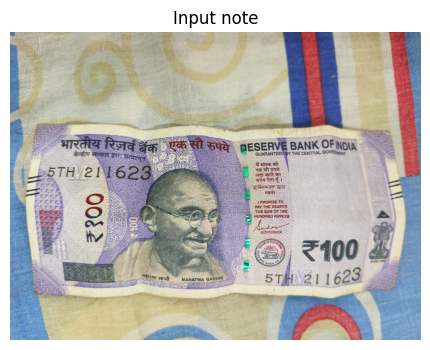

In [16]:

# =============================================================================
# 3a - UPLOAD AN IMAGE (VS CODE)
# =============================================================================

from tkinter import Tk, filedialog
import os
import cv2
import matplotlib.pyplot as plt

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

IMAGE_PATH = filedialog.askopenfilename(
    title="Select Indian Currency Image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png"),
        ("All files", "*.*")
    ]
)

root.destroy()

assert IMAGE_PATH, "No image selected."

img = cv2.imread(IMAGE_PATH)

assert img is not None, (
    "Could not decode %s" % IMAGE_PATH
)

print(
    "Loaded %s - %dx%d px"
    % (
        os.path.basename(IMAGE_PATH),
        img.shape[1],
        img.shape[0]
    )
)

plt.figure(figsize=(7, 4))

plt.imshow(
    cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.title("Input note")
plt.show()


---## 4 · Run the full analysis

In [17]:
# ---- 3c: run the complete detection pipeline -------------------------------

result = run_pipeline(img)

prep = result["preprocessing"]

print("VERDICT      :", result["verdict"])

print(
    "Denomination : %s (%s%% confidence)"
    % (
        result["denomination"]["denomination"],
        result["denomination"]["confidence"]
    )
)

print(
    "Authenticity : %s (real %s%% / fake %s%%)"
    % (
        result["auth"]["status"],
        result["auth"]["real_probability"],
        result["auth"]["fake_probability"]
    )
)

print(
    "Risk score   : %s%%   System confidence: %s%%"
    % (
        result["risk_score"],
        result["confidence"]
    )
)

print(
    "Security     : %s/%s features verified"
    % (
        result["security"]["passed_features"],
        result["security"]["total_features"]
    )
)

print(
    "Alarm        :",
    "TRIGGERED" if result["trigger_alarm"] else "not triggered"
)

VERDICT      : SUSPECT / WARNING
Denomination : Rs.100 (One Hundred Rupee) (99.86% confidence)
Authenticity : GENUINE (real 99.54% / fake 0.46%)
Risk score   : 12.2%   System confidence: 88.2%
Security     : 4/5 features verified
Alarm        : TRIGGERED


---## 5 · Stage 2 — image-quality checkIs the photo clear enough to analyse? If the quality score falls below 35 the pipeline refuses togive a verdict and asks for a re-scan rather than guessing.Watch the **aligned** flag in the preprocessing strip: when it is `False` the note was notdetected as a quadrilateral, so the fixed security-feature regions in §8 are not properlyregistered and their scores are much less reliable.

Quality score : 90.61%   PASS
Blur variance : 2528.68  (80 or more wanted)
Brightness    : 168.06/255
Glare ratio   : 0.00%
Resolution    : 1600x1200 px

No quality warnings.


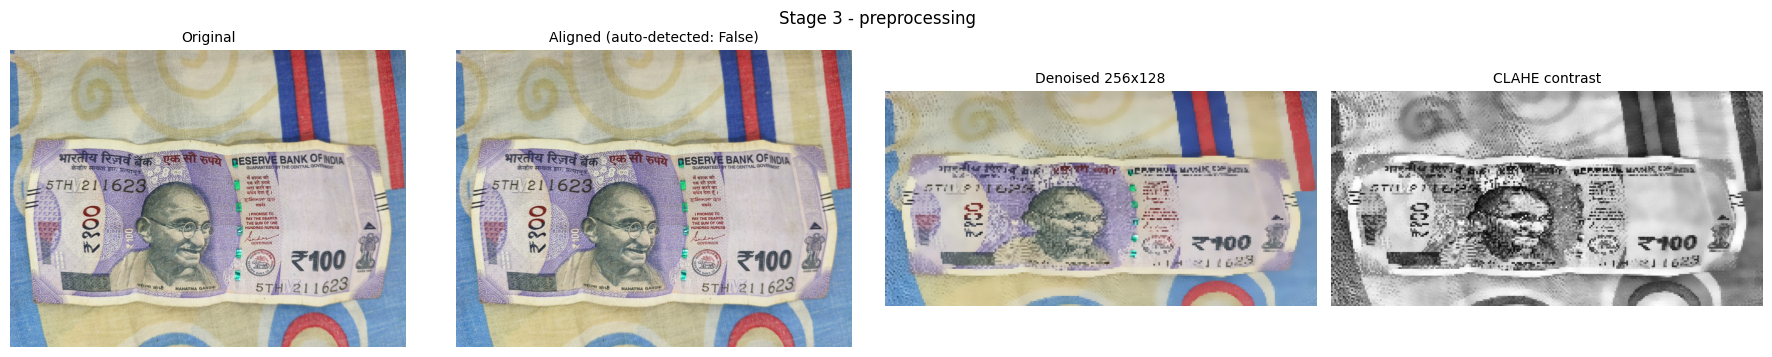

In [18]:
# ---- Stage 3: preprocessing results -----------------------------------------

q = result["quality"]

print(
    "Quality score : %s%%   %s"
    % (
        q["quality_score"],
        "PASS" if q["passed"] else "FAIL"
    )
)

print(
    "Blur variance : %s  (80 or more wanted)"
    % q["blur_variance"]
)

print(
    "Brightness    : %s/255"
    % q["brightness_mean"]
)

print(
    "Glare ratio   : %.2f%%"
    % (q["glare_ratio"] * 100)
)

print(
    "Resolution    : %dx%d px"
    % (
        q["resolution"][0],
        q["resolution"][1]
    )
)

if q["warnings"]:
    print("\nWarnings:")

    for w in q["warnings"]:
        print("  -", w)

else:
    print("\nNo quality warnings.")


panels = [
    (
        "Original",
        cv2.cvtColor(
            prep["original"],
            cv2.COLOR_BGR2RGB
        )
    ),

    (
        "Aligned (auto-detected: %s)" % prep["aligned_success"],
        cv2.cvtColor(
            prep["aligned"],
            cv2.COLOR_BGR2RGB
        )
    ),

    (
        "Denoised 256x128",
        cv2.cvtColor(
            prep["denoised_bgr"],
            cv2.COLOR_BGR2RGB
        )
    ),

    (
        "CLAHE contrast",
        prep["clahe_gray"]
    )
]


fig, ax = plt.subplots(
    1,
    4,
    figsize=(18, 3.6)
)

for a, (t, im) in zip(ax, panels):

    a.imshow(
        im,
        cmap="gray" if im.ndim == 2 else None
    )

    a.set_title(t, fontsize=10)
    a.axis("off")


plt.suptitle(
    "Stage 3 - preprocessing",
    fontsize=12
)

plt.tight_layout()
plt.show()

---## 6 · Stage 4 — denomination detectionSix classes: ₹10, ₹20, ₹50, ₹100, ₹200, ₹500. ₹2000 is out of circulation and deliberatelyexcluded from the model.

Predicted denomination : Rs.100 (One Hundred Rupee)
Confidence             : 99.86%
Colour profile         : Lavender
Model                  : Dedicated 6-class denomination CNN


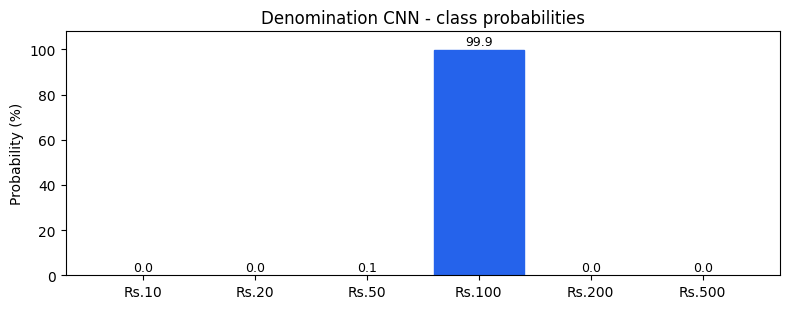

In [19]:
# ---- Denomination analysis -----------------------------------------------

d = result["denomination"]

print("Predicted denomination :", d["denomination"])
print("Confidence             : %s%%" % d["confidence"])
print("Colour profile         :", d["color_profile"])
print("Model                  :", d["model_used"])

probs = d.get("all_probabilities") or {}

if probs:
    names = list(probs.keys())
    vals = list(probs.values())

    top = int(np.argmax(vals))

    plt.figure(figsize=(8, 3.2))

    bars = plt.bar(names, vals)

    bars[top].set_color("#2563eb")

    plt.ylabel("Probability (%)")
    plt.ylim(0, 108)
    plt.title("Denomination CNN - class probabilities")

    for b, v in zip(bars, vals):
        plt.text(
            b.get_x() + b.get_width() / 2,
            v + 2,
            "%.1f" % v,
            ha="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

---## 7 · Stage 5 — genuine vs counterfeitThe binary CNN outputs P(fake) directly. This is the *network's* opinion alone — the final verdictin §11 fuses it with the security-feature audit, which is allowed to overrule it.

CNN verdict       : GENUINE
P(genuine)        : 99.54%
P(counterfeit)    : 0.46%
Model             : Dedicated authentication CNN

Intaglio texture  : 100.0%  (laplacian 13786.78, edge energy 45033.66)
Flat print-like   : False


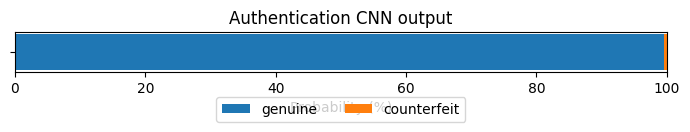

In [20]:
# ---- Authentication analysis -----------------------------------------------

a = result["auth"]

print("CNN verdict       :", a["status"])
print("P(genuine)        : %s%%" % a["real_probability"])
print("P(counterfeit)    : %s%%" % a["fake_probability"])
print("Model             :", a["model_used"])

it = a["intaglio"]

print(
    "\nIntaglio texture  : %s%%  (laplacian %s, edge energy %s)"
    % (
        it["intaglio_score"],
        it["laplacian_var"],
        it["edge_energy"]
    )
)

print("Flat print-like   :", it["is_flat_print"])


plt.figure(figsize=(7, 1.9))

plt.barh(
    [""],
    [a["real_probability"]],
    label="genuine"
)

plt.barh(
    [""],
    [a["fake_probability"]],
    left=[a["real_probability"]],
    label="counterfeit"
)

plt.xlim(0, 100)
plt.xlabel("Probability (%)")

plt.legend(
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.45)
)

plt.title("Authentication CNN output")

plt.tight_layout()
plt.show()

---## 7b · Stage 5b — novelty / play-money checkCatches toy notes, `Children Bank of India` notes and film props by reading the note's own text.A match here overrides everything else in the pipeline.

In [21]:
# ---- Novelty / play-money OCR analysis --------------------------------------

nov = result["novelty"]

if not nov["available"]:

    print("NOT CHECKED -", nov["note"])

    print(
        "\nInstall OCR by re-running cell 0, "
        "or this stage stays skipped."
    )

    print(
        "Note: 'not checked' is NOT the same as "
        "'no novelty text found'."
    )

elif nov["is_novelty"]:

    print("NOVELTY / PLAY-MONEY NOTE DETECTED")

    print(
        "Matched text :",
        ", ".join(
            p.upper()
            for p in nov["matched_phrases"]
        )
    )

    print(
        "RBI text     :",
        "found" if nov["rbi_text_found"] else "NOT found"
    )

    print(
        "\nThis overrides the CNN and "
        "the security-feature audit."
    )

else:

    print("No novelty text found on the note.")

    print(
        "RBI text     :",
        "found" if nov["rbi_text_found"] else "NOT found"
    )

    if not nov["rbi_text_found"]:

        print(
            "\nNote: the RESERVE BANK OF INDIA text "
            "was not read either."
        )

        print(
            "That is usually an OCR miss on a "
            "low-resolution photo rather than evidence,"
        )

        print(
            "so it is not scored."
        )


print(
    "\n--- OCR text read from the note "
    "(first 600 chars) ---"
)

print(
    nov["ocr_text"]
    if nov["ocr_text"]
    else "(nothing read)"
)

No novelty text found on the note.
RBI text     : NOT found

Note: the RESERVE BANK OF INDIA text was not read either.
That is usually an OCR miss on a low-resolution photo rather than evidence,
so it is not scored.

--- OCR text read from the note (first 600 chars) ---
(nothing read)


---## 8 · Stage 6 — security-feature analysisFive features a genuine note must show. Each is measured inside its own region of the alignednote, with a test matched to what that feature physically is — a smooth tonal gradient for thewatermark, dominant vertical gradients for the metallic thread, high-frequency line density formicro-lettering, and so on. Anything scoring below 45 is reported as **suspicious or missing**.

4/5 features verified (80.0% pass ratio)



Security feature,Status,Score,Measurement,Region
Mahatma Gandhi WatermarkMulti-tonal paper portrait watermark,✘ Suspicious / Missing,10.0%,"Watermark pattern appears suspicious (tonal spread 56.9, edge density 29.5%)",
Windowed Security ThreadVertical metallic security thread,✔ Verified,55.0%,"Metallic thread structure detected (ratio 0.50, gradient 86.4, hue spread 43.9)",
Bleed Lines and Micro-letteringTactile bleed lines and micro-lettering,✔ Verified,100.0%,Bleed-line density 109.8,
Latent Image and NumeralDenomination numeral latent image,✔ Verified,100.0%,Latent-image texture variance 8064.8,
See-Through RegisterOverlapping see-through register,✔ Verified,100.0%,Register print density 35.23%,

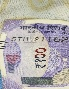
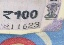

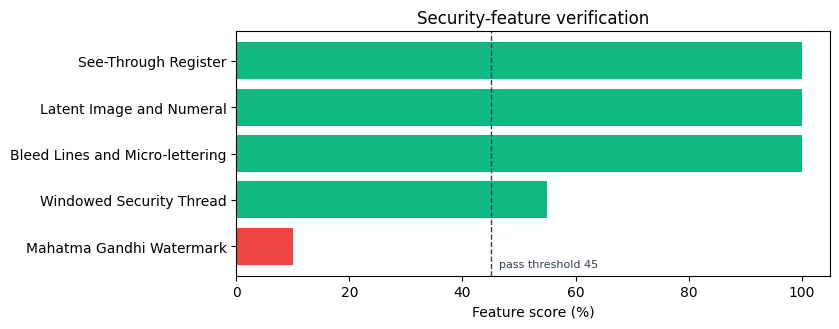

In [22]:
# ---- Security-feature verification ------------------------------------------

sec = result["security"]

print(
    "%s/%s features verified (%s%% pass ratio)\n"
    % (
        sec["passed_features"],
        sec["total_features"],
        sec["pass_ratio"]
    )
)

rows = ""

for f in sec["feature_details"].values():

    ok = f["passed"]

    rows += (
        "<tr>"
        "<td style='padding:7px 10px'>"
        "<b>%s</b>"
        "<div style='color:#64748b;font-size:11px'>%s</div>"
        "</td>"

        "<td style='padding:7px 10px;text-align:center;"
        "font-weight:700;color:%s'>%s</td>"

        "<td style='padding:7px 10px;text-align:center'>%s%%</td>"

        "<td style='padding:7px 10px;font-size:11px;"
        "color:#475569'>%s</td>"

        "<td style='padding:4px'>"
        "<img src='%s' style='height:46px;border-radius:3px'>"
        "</td>"

        "</tr>"
        % (
            f["name"],
            f["description"],
            "#059669" if ok else "#dc2626",
            "&#10004; Verified"
            if ok
            else "&#10008; " + f["status"],
            f["score"],
            f["details"],
            f["crop_base64"]
        )
    )


display(
    HTML(
        "<table style='border-collapse:collapse;width:100%;"
        "font-family:system-ui,sans-serif;font-size:13px'>"

        "<thead>"
        "<tr style='background:#f1f5f9'>"
        "<th style='padding:8px;text-align:left'>Security feature</th>"
        "<th style='padding:8px'>Status</th>"
        "<th style='padding:8px'>Score</th>"
        "<th style='padding:8px;text-align:left'>Measurement</th>"
        "<th style='padding:8px'>Region</th>"
        "</tr>"
        "</thead>"

        "<tbody>"
        + rows +
        "</tbody>"

        "</table>"
    )
)


names = [
    f["name"]
    for f in sec["feature_details"].values()
]

scores = [
    f["score"]
    for f in sec["feature_details"].values()
]

cols = [
    "#10b981" if f["passed"] else "#ef4444"
    for f in sec["feature_details"].values()
]


plt.figure(figsize=(8.5, 3.4))

plt.barh(
    names,
    scores,
    color=cols
)

plt.axvline(
    45,
    ls="--",
    c="#334155",
    lw=1
)

plt.text(
    46.5,
    -0.45,
    "pass threshold 45",
    fontsize=8,
    color="#334155"
)

plt.xlim(0, 105)
plt.xlabel("Feature score (%)")
plt.title("Security-feature verification")

plt.tight_layout()
plt.show()

---## 8b · Why — how this note differs from a genuine oneFor every feature that failed, this is the measurement a genuine note produces, the measurement*this* note produced, and what the gap physically means. This is the answer to "why is itcounterfeit" in concrete terms rather than a bare label.

In [23]:
# ---- XAI: comparison with genuine baseline ---------------------------------

diffs = result["xai_report"]["differences"]

if not diffs:

    print(
        "No measurable deviation from a genuine note - "
        "every security feature fell inside its expected range."
    )

else:

    print(
        "%d feature(s) deviate from the genuine baseline:\n"
        % len(diffs)
    )

    for d in diffs:

        print("-" * 76)

        print("FEATURE      :", d["feature"])
        print("METRIC       :", d["metric"])
        print("GENUINE NOTE :", d["genuine"])
        print("THIS NOTE    :", d["this_note"])

        print("DIFFERENCE   :")

        for line in __import__("textwrap").wrap(
            d["difference"],
            70
        ):
            print("   ", line)

    print("-" * 76)

    rows = "".join(
        "<tr>"
        "<td style='padding:7px 10px;vertical-align:top'>"
        "<b>%s</b>"
        "<div style='color:#64748b;font-size:11px'>%s</div>"
        "</td>"

        "<td style='padding:7px 10px;vertical-align:top;"
        "color:#059669'>%s</td>"

        "<td style='padding:7px 10px;vertical-align:top;"
        "color:#dc2626'>%s</td>"

        "<td style='padding:7px 10px;vertical-align:top;"
        "font-size:12px'>%s</td>"

        "</tr>"
        % (
            d["feature"],
            d["metric"],
            d["genuine"],
            d["this_note"],
            d["difference"]
        )

        for d in diffs
    )

    display(
        HTML(
            "<table style='border-collapse:collapse;width:100%;"
            "font-family:system-ui,sans-serif;font-size:13px'>"

            "<thead>"
            "<tr style='background:#f1f5f9'>"

            "<th style='padding:8px;text-align:left'>"
            "Feature"
            "</th>"

            "<th style='padding:8px;text-align:left'>"
            "A genuine note reads"
            "</th>"

            "<th style='padding:8px;text-align:left'>"
            "This note reads"
            "</th>"

            "<th style='padding:8px;text-align:left'>"
            "What the difference means"
            "</th>"

            "</tr>"
            "</thead>"

            "<tbody>"
            + rows +
            "</tbody>"

            "</table>"
        )
    )

1 feature(s) deviate from the genuine baseline:

----------------------------------------------------------------------------
FEATURE      : Mahatma Gandhi Watermark
METRIC       : Tonal spread and edge density
GENUINE NOTE : Tonal spread 10-55 with edge density under 18%
THIS NOTE    : tonal spread 56.9, edge density 29.5%
DIFFERENCE   :
    The observed tonal/edge pattern differs from the expected smooth
    watermark pattern.
----------------------------------------------------------------------------


Feature,A genuine note reads,This note reads,What the difference means
Mahatma Gandhi WatermarkTonal spread and edge density,Tonal spread 10-55 with edge density under 18%,"tonal spread 56.9, edge density 29.5%",The observed tonal/edge pattern differs from the expected smooth watermark pattern.


---## 9 · Stage 7 — suspicious-region localisationEvery feature that failed is named and boxed on the note, so the output points at *where* theproblem is instead of only reporting that there is one.

1 SUSPICIOUS REGION(S) DETECTED

  [HIGH  ] Mahatma Gandhi Watermark
           Failed verification (score 10.0%)
           bounding box x=12 y=19 w=69 h=89



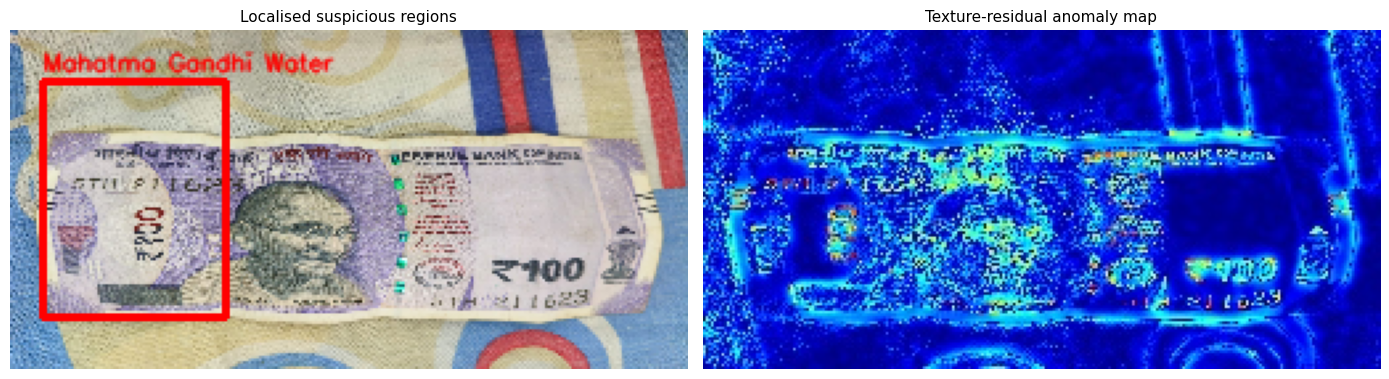

In [24]:
an = result["anomaly"]

if an["has_anomalies"]:
    print("%d SUSPICIOUS REGION(S) DETECTED\n" % an["anomaly_count"])

    for s in an["suspicious_regions"]:
        x, y, w, h = s["bbox"]

        print("  [%-6s] %s" % (s["severity"], s["feature"]))
        print("           %s" % s["reason"])
        print(
            "           bounding box x=%d y=%d w=%d h=%d\n"
            % (x, y, w, h)
        )

else:
    print("No suspicious regions - all security features verified.")


diff = cv2.imdecode(
    np.frombuffer(
        base64.b64decode(
            an["diff_map_base64"].split(",")[1]
        ),
        np.uint8
    ),
    cv2.IMREAD_COLOR
)


fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].imshow(
    cv2.cvtColor(an["annotated"], cv2.COLOR_BGR2RGB)
)
ax[0].set_title(
    "Localised suspicious regions",
    fontsize=11
)

ax[1].imshow(
    cv2.cvtColor(diff, cv2.COLOR_BGR2RGB)
)
ax[1].set_title(
    "Texture-residual anomaly map",
    fontsize=11
)


for a_ in ax:
    a_.axis("off")

plt.tight_layout()
plt.show()

---## 10 · Stage 8 — Grad-CAM explainabilityOriginal note → Grad-CAM overlay. Red and yellow mark the pixels whose activations most changedthe authentication output, so the decision can be inspected rather than taken on faith.

Explainability source: Grad-CAM on convolutional layer 'conv2d_3'


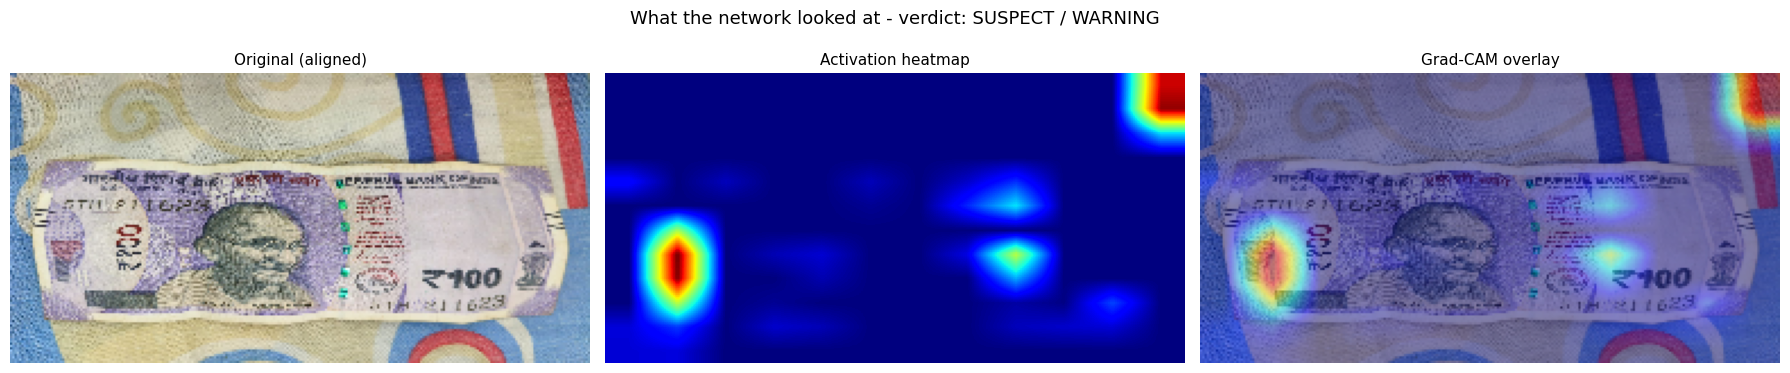

In [25]:
gc = result["gradcam"]

print("Explainability source:", gc["layer_used"])


fig, ax = plt.subplots(1, 3, figsize=(18, 4))


ax[0].imshow(
    cv2.cvtColor(
        prep["resized_bgr"],
        cv2.COLOR_BGR2RGB
    )
)
ax[0].set_title(
    "Original (aligned)",
    fontsize=11
)


ax[1].imshow(
    gc["heatmap_raw"],
    cmap="jet"
)
ax[1].set_title(
    "Activation heatmap",
    fontsize=11
)


ax[2].imshow(
    cv2.cvtColor(
        gc["superimposed"],
        cv2.COLOR_BGR2RGB
    )
)
ax[2].set_title(
    "Grad-CAM overlay",
    fontsize=11
)


for a_ in ax:
    a_.axis("off")


plt.suptitle(
    "What the network looked at - verdict: %s"
    % result["verdict"],
    fontsize=13
)

plt.tight_layout()
plt.show()

---## 11 · Stage 9 — overall reviewEvery score in one place, plus how the risk number was composed.

Denomination confidence,99.86%
CNN probability genuine,99.54%
CNN probability counterfeit,0.46%
Security features passed,4/5 (80.0%)
Suspicious regions,1
Image quality,90.61%
Composite risk score,12.2%
System confidence,88.2%
Print-forgery pattern,no


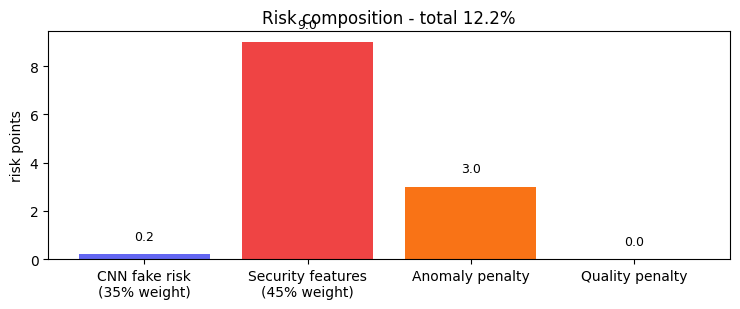

In [26]:
r = result["risk"]
b = r["breakdown"]


display(
    HTML(
        """
        <div style="
            font-family:system-ui,sans-serif;
            border:2px solid {colour};
            border-radius:10px;
            padding:18px;
            max-width:780px
        ">

            <div style="
                font-size:26px;
                font-weight:800;
                color:{colour}
            ">
                {verdict}
            </div>

            <div style="
                color:#475569;
                margin:4px 0 14px
            ">
                {denom} &nbsp;&middot;&nbsp; analysed {ts}
            </div>

            <table style="
                width:100%;
                border-collapse:collapse;
                font-size:13px
            ">

                <tr>
                    <td style="padding:5px 0">
                        Denomination confidence
                    </td>
                    <td style="text-align:right">
                        <b>{dconf}%</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        CNN probability genuine
                    </td>
                    <td style="text-align:right">
                        <b>{real}%</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        CNN probability counterfeit
                    </td>
                    <td style="text-align:right">
                        <b>{fake}%</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        Security features passed
                    </td>
                    <td style="text-align:right">
                        <b>{sp}/{st} ({sr}%)</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        Suspicious regions
                    </td>
                    <td style="text-align:right">
                        <b>{nreg}</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        Image quality
                    </td>
                    <td style="text-align:right">
                        <b>{qual}%</b>
                    </td>
                </tr>

                <tr style="border-top:1px solid #e2e8f0">
                    <td style="padding:7px 0">
                        Composite risk score
                    </td>
                    <td style="text-align:right;color:{colour}">
                        <b>{risk}%</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        System confidence
                    </td>
                    <td style="text-align:right">
                        <b>{conf}%</b>
                    </td>
                </tr>

                <tr>
                    <td style="padding:5px 0">
                        Print-forgery pattern
                    </td>
                    <td style="text-align:right">
                        <b>{forgery}</b>
                    </td>
                </tr>

            </table>

        </div>
        """.format(
            colour=r["status_color"],
            verdict=r["verdict"],
            denom=result["denomination"]["denomination"],
            ts=result["xai_report"]["timestamp"],
            dconf=result["denomination"]["confidence"],
            real=result["auth"]["real_probability"],
            fake=result["auth"]["fake_probability"],
            sp=result["security"]["passed_features"],
            st=result["security"]["total_features"],
            sr=result["security"]["pass_ratio"],
            nreg=result["anomaly"]["anomaly_count"],
            qual=result["quality"]["quality_score"],
            risk=r["risk_score"],
            conf=r["confidence"],
            forgery="YES" if r["is_print_forgery"] else "no"
        )
    )
)


labels = [
    "CNN fake risk\n(35% weight)",
    "Security features\n(45% weight)",
    "Anomaly penalty",
    "Quality penalty"
]

vals = [
    b["fake_classifier_risk"],
    b["security_feature_risk"],
    b["anomaly_penalty"],
    b["quality_penalty"]
]


plt.figure(figsize=(7.5, 3.2))

bars = plt.bar(
    labels,
    vals,
    color=[
        "#6366f1",
        "#ef4444",
        "#f97316",
        "#f59e0b"
    ]
)


for bar, v in zip(bars, vals):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        v + 0.6,
        str(v),
        ha="center",
        fontsize=9
    )


plt.ylabel("risk points")

plt.title(
    "Risk composition - total %s%%"
    % r["risk_score"]
)

plt.tight_layout()
plt.show()

---## 12 · Stage 10 — counterfeit alarmIf the verdict is counterfeit or suspect, a siren plays automatically. Colab renders it as anautoplaying audio widget, so make sure the browser tab is not muted.

In [32]:
# =============================================================================
# AUTOMATIC AUDIO ALARM FOR SUSPECT / COUNTERFEIT
# =============================================================================

def counterfeit_alarm(sr=22050, seconds=2.2):

    t = np.linspace(
        0,
        seconds,
        int(sr * seconds),
        endpoint=False
    )

    sweep = (
        800
        + 350 * np.sin(2 * np.pi * 2.2 * t)
    )

    wave = (
        0.55
        * np.sin(
            2 * np.pi * np.cumsum(sweep) / sr
        )
    )

    envelope = np.clip(
        np.sin(np.pi * t / seconds) * 1.6,
        0,
        1
    )

    return wave * envelope, sr


# Get final verdict
verdict = result["verdict"].upper()

# Check whether alarm is required
if "SUSPECT" in verdict or "COUNTERFEIT" in verdict:

    print("WARNING: SUSPICIOUS OR COUNTERFEIT NOTE DETECTED!")

    display(
        HTML(
            """
            <div style="
                background:#7f1d1d;
                color:white;
                padding:18px;
                border-radius:10px;
                font-family:system-ui,sans-serif;
            ">

                <div style="
                    font-size:24px;
                    font-weight:800;
                ">
                    &#9888; {verdict} ALERT
                </div>

                <div style="margin-top:8px">
                    Denomination: <b>{denom}</b>
                    <br>
                    Risk Score: <b>{risk}%</b>
                    <br>
                    Do not accept this note.
                </div>

            </div>
            """.format(
                verdict=verdict,
                denom=result["denomination"]["denomination"],
                risk=result["risk"]["risk_score"]
            )
        )
    )

    # Generate and play siren automatically
    wave, sr = counterfeit_alarm()

    display(
        Audio(
            wave,
            rate=sr,
            autoplay=True
        )
    )

else:

    print("NO ALARM - Verdict:", verdict)

    display(
        HTML(
            """
            <div style="
                background:#064e3b;
                color:white;
                padding:18px;
                border-radius:10px;
                font-family:system-ui,sans-serif;
            ">

                <div style="
                    font-size:24px;
                    font-weight:800;
                ">
                    &#10004; NO ALARM
                </div>

                <div style="margin-top:8px">
                    Denomination: <b>{denom}</b>
                    <br>
                    Verdict: <b>{verdict}</b>
                    <br>
                    Risk Score: <b>{risk}%</b>
                </div>

            </div>
            """.format(
                denom=result["denomination"]["denomination"],
                verdict=verdict,
                risk=result["risk"]["risk_score"]
            )
        )
    )

---## 13 · Stage 11 — explainable-AI reportThe narrative report: what note this is, whether it is genuine, and **why** — which measurementsdrove the verdict, which features failed, and what the Grad-CAM attention means. It renders belowand is saved as a self-contained HTML file (all images embedded) plus a JSON of the raw numbers.


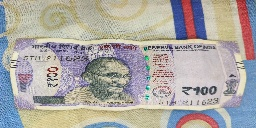
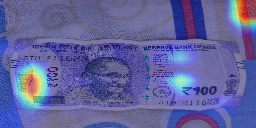
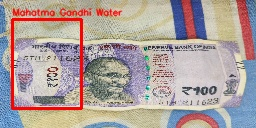
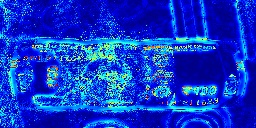


Saved outputs/currency_xai_report.html and outputs/currency_result.json


In [ ]:
xr = result["xai_report"]


def md_to_html(s):
    """
    Minimal **bold** / *italic* to HTML,
    so the narrative renders as written.
    """

    s = re.sub(
        r"\*\*(.+?)\*\*",
        r"<b>\1</b>",
        s
    )

    s = re.sub(
        r"(?<!\*)\*([^*]+?)\*(?!\*)",
        r"<i>\1</i>",
        s
    )

    return s


# ---------------------------------------------------------
# SECURITY CHECKLIST
# ---------------------------------------------------------

checklist_rows = "".join(
    "<tr>"
    "<td style='padding:6px 10px'><b>%s</b></td>"
    "<td style='padding:6px 10px;text-align:center;color:%s'>"
    "<b>%s</b></td>"
    "<td style='padding:6px 10px;text-align:center'>%s</td>"
    "<td style='padding:6px 10px;font-size:11.5px;color:#475569'>%s</td>"
    "</tr>"
    % (
        c["feature"],
        "#059669" if "Verified" in c["status"] else "#dc2626",
        c["status"],
        c["score"],
        c["details"]
    )
    for c in xr["security_checklist"]
)


# ---------------------------------------------------------
# QUALITY METRICS
# ---------------------------------------------------------

quality_rows = "".join(
    "<tr>"
    "<td style='padding:5px 10px'>%s</td>"
    "<td style='padding:5px 10px;text-align:right'><b>%s</b></td>"
    "</tr>"
    % (k, v)
    for k, v in xr["quality_metrics"].items()
)


# ---------------------------------------------------------
# DIFFERENCES FROM GENUINE BASELINE
# ---------------------------------------------------------

if xr["differences"]:

    diff_rows = "".join(
        "<tr>"
        "<td style='padding:7px 10px;vertical-align:top'>"
        "<b>%s</b>"
        "<div style='color:#64748b;font-size:11px'>%s</div>"
        "</td>"

        "<td style='padding:7px 10px;vertical-align:top;color:#059669'>"
        "%s"
        "</td>"

        "<td style='padding:7px 10px;vertical-align:top;color:#dc2626'>"
        "%s"
        "</td>"

        "<td style='padding:7px 10px;vertical-align:top;font-size:12px'>"
        "%s"
        "</td>"

        "</tr>"
        % (
            d["feature"],
            d["metric"],
            d["genuine"],
            d["this_note"],
            d["difference"]
        )
        for d in xr["differences"]
    )

    diff_section = (
        "<table style='border-collapse:collapse;width:100%;font-size:13px;"
        "border:1px solid #e2e8f0'>"

        "<thead>"
        "<tr style='background:#f1f5f9'>"
        "<th style='padding:8px;text-align:left'>Feature</th>"
        "<th style='padding:8px;text-align:left'>A genuine note reads</th>"
        "<th style='padding:8px;text-align:left'>This note reads</th>"
        "<th style='padding:8px;text-align:left'>What the difference means</th>"
        "</tr>"
        "</thead>"

        "<tbody>"
        + diff_rows
        + "</tbody>"
        "</table>"
    )

else:

    diff_section = (
        "<p>"
        "No measurable deviation from a genuine note &mdash; "
        "every security feature fell inside its expected range."
        "</p>"
    )


# ---------------------------------------------------------
# SUSPICIOUS REGIONS
# ---------------------------------------------------------

region_rows = "".join(
    "<li>"
    "<b>%s</b> &mdash; %s "
    "<span style='color:#64748b'>"
    "(severity %s, box x=%d y=%d w=%d h=%d)"
    "</span>"
    "</li>"
    % (
        s["feature"],
        s["reason"],
        s["severity"],
        s["bbox"][0],
        s["bbox"][1],
        s["bbox"][2],
        s["bbox"][3]
    )
    for s in result["anomaly"]["suspicious_regions"]
)


if not region_rows:
    region_rows = (
        "<li>"
        "None &mdash; every security feature verified."
        "</li>"
    )


# ---------------------------------------------------------
# SUMMARY AND REASONS
# ---------------------------------------------------------

summary_html = "".join(
    "<p>%s</p>" % md_to_html(p)
    for p in xr["summary_paragraphs"]
)


reasons_html = "".join(
    "<li>%s</li>" % md_to_html(b)
    for b in xr["bullet_reasons"]
)


# ---------------------------------------------------------
# COMPLETE HTML REPORT
# ---------------------------------------------------------

report_html = """
<!DOCTYPE html>

<html>

<head>
    <meta charset="utf-8">
    <title>Currency Authentication Report</title>
</head>


<body style="
    font-family:system-ui,-apple-system,Segoe UI,sans-serif;
    max-width:900px;
    margin:26px auto;
    color:#0f172a;
    line-height:1.6
">


<h1 style="margin-bottom:2px">
    Currency Authentication Report
</h1>


<div style="
    color:#64748b;
    font-size:13px
">
    Explainable-AI counterfeit detection
    &middot;
    generated {ts}
</div>


<div style="
    background:{colour}18;
    border-left:6px solid {colour};
    padding:14px 18px;
    margin:18px 0;
    border-radius:6px
">

    <div style="
        font-size:13px;
        color:#475569;
        text-transform:uppercase;
        letter-spacing:.5px
    ">
        Verdict
    </div>

    <div style="
        font-size:28px;
        font-weight:800;
        color:{colour}
    ">
        {verdict}
    </div>

    <div style="margin-top:4px">
        <b>{denom}</b>
        &middot;
        denomination confidence {dconf}%
        &middot;
        risk score {risk}%
        &middot;
        system confidence {conf}%
    </div>

</div>


<h2>1. What this note is, and the decision</h2>

{summary}


<h2>2. Why the model decided this</h2>

<ul>
    {reasons}
</ul>


<h2>3. Security-feature audit</h2>

<table style="
    border-collapse:collapse;
    width:100%;
    font-size:13px;
    border:1px solid #e2e8f0
">

<thead>

<tr style="background:#f1f5f9">

<th style="padding:8px;text-align:left">
    Feature
</th>

<th style="padding:8px">
    Status
</th>

<th style="padding:8px">
    Score
</th>

<th style="padding:8px;text-align:left">
    Measurement
</th>

</tr>

</thead>

<tbody>

{checklist}

</tbody>

</table>


<h2>4. How this note differs from a genuine one</h2>

{differences}


<h2>5. Suspicious regions located</h2>

<ul>
    {regions}
</ul>


<h2>6. Grad-CAM explainability</h2>

<p>
    {xai}
</p>


<table>

<tr>

<td style="text-align:center;padding:8px">

<img
    src="{orig_img}"
    style="width:330px;border-radius:6px"
>

<div style="
    font-size:12px;
    color:#64748b
">
    Original note (aligned)
</div>

</td>


<td style="text-align:center;padding:8px">

<img
    src="{cam_img}"
    style="width:330px;border-radius:6px"
>

<div style="
    font-size:12px;
    color:#64748b
">
    Grad-CAM overlay
</div>

</td>

</tr>


<tr>

<td style="text-align:center;padding:8px">

<img
    src="{ann_img}"
    style="width:330px;border-radius:6px"
>

<div style="
    font-size:12px;
    color:#64748b
">
    Localised suspicious regions
</div>

</td>


<td style="text-align:center;padding:8px">

<img
    src="{diff_img}"
    style="width:330px;border-radius:6px"
>

<div style="
    font-size:12px;
    color:#64748b
">
    Texture-residual map
</div>

</td>

</tr>

</table>


<h2>7. Scan quality</h2>

<table style="
    border-collapse:collapse;
    font-size:13px;
    border:1px solid #e2e8f0
">

{quality}

</table>


<h2>8. Risk composition</h2>

<table style="
    border-collapse:collapse;
    font-size:13px;
    border:1px solid #e2e8f0
">


<tr>

<td style="padding:5px 10px">
    CNN counterfeit risk (35% weight)
</td>

<td style="padding:5px 10px;text-align:right">
    <b>{bd_fake}</b>
</td>

</tr>


<tr>

<td style="padding:5px 10px">
    Security-feature risk (45% weight)
</td>

<td style="padding:5px 10px;text-align:right">
    <b>{bd_sec}</b>
</td>

</tr>


<tr>

<td style="padding:5px 10px">
    Anomaly penalty
</td>

<td style="padding:5px 10px;text-align:right">
    <b>{bd_an}</b>
</td>

</tr>


<tr>

<td style="padding:5px 10px">
    Quality penalty
</td>

<td style="padding:5px 10px;text-align:right">
    <b>{bd_q}</b>
</td>

</tr>


<tr style="background:#f8fafc">

<td style="padding:5px 10px">
    <b>Total risk score</b>
</td>

<td style="padding:5px 10px;text-align:right">
    <b>{risk}%</b>
</td>

</tr>


</table>


<p style="
    margin-top:26px;
    font-size:12px;
    color:#64748b;
    border-top:1px solid #e2e8f0;
    padding-top:12px
">

Automated screening aid. A flat photograph cannot capture
intaglio relief, UV fluorescence or optically variable ink,
so this report is not a legal determination of authenticity.
Refer any flagged note to a bank or to the RBI for physical
verification.

</p>


</body>

</html>
""".format(
    ts=xr["timestamp"],
    colour=result["status_color"],
    verdict=xr["verdict"],
    denom=xr["denom_name"],
    dconf=result["denomination"]["confidence"],
    risk=xr["risk_score"],
    conf=xr["confidence"],
    summary=summary_html,
    reasons=reasons_html,
    checklist=checklist_rows,
    regions=region_rows,
    differences=diff_section,
    xai=md_to_html(xr["xai_explanation"]),
    orig_img=to_base64_img(prep["resized_bgr"]),
    cam_img=result["gradcam"]["superimposed_base64"],
    ann_img=result["anomaly"]["annotated_base64"],
    diff_img=result["anomaly"]["diff_map_base64"],
    quality=quality_rows,
    bd_fake=result["risk"]["breakdown"]["fake_classifier_risk"],
    bd_sec=result["risk"]["breakdown"]["security_feature_risk"],
    bd_an=result["risk"]["breakdown"]["anomaly_penalty"],
    bd_q=result["risk"]["breakdown"]["quality_penalty"]
)


# ---------------------------------------------------------
# SAVE HTML REPORT
# ---------------------------------------------------------

REPORT_PATH = "outputs/currency_xai_report.html"

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:
    f.write(report_html)


# ---------------------------------------------------------
# SAVE JSON RESULTS
# ---------------------------------------------------------

JSON_PATH = "outputs/currency_result.json"


serialisable = dict(
    (
        k,
        v
    )
    for k, v in result.items()
    if k not in (
        "preprocessing",
        "gradcam",
        "anomaly"
    )
)


serialisable["gradcam_layer"] = (
    result["gradcam"]["layer_used"]
)


serialisable["anomaly"] = dict(
    (
        k,
        v
    )
    for k, v in result["anomaly"].items()
    if k != "annotated"
)


with open(
    JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        serialisable,
        f,
        indent=2,
        default=str
    )


# ---------------------------------------------------------
# DISPLAY REPORT
# ---------------------------------------------------------

display(
    HTML(report_html)
)


print(
    "\nSaved %s and %s"
    % (
        REPORT_PATH,
        JSON_PATH
    )
)

### Download the report

In [ ]:
from google.colab import files

files.download(REPORT_PATH)
files.download(JSON_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---## 14 · Batch mode (optional)Score a whole folder at once — useful for sanity-checking the models against a test split.

---## What this system can and cannot do**The design choice that matters most.** The security-feature audit is allowed to overrule theCNN. If two or more features fail, the verdict is counterfeit no matter how confident the networkis that the note is real. That is deliberate: a good colour-laser forgery reproduces the*appearance* the CNN learned, but it cannot reproduce embedded thread metal, multi-tonal watermarkpaper, or raised intaglio ink — which is what the classical tests actually measure.**Real limits, stated plainly.*** The five feature regions are fixed fractions of a 256×128 aligned note. When `aligned_success`  is `False` (shown in §5) the note was not detected as a quadrilateral, the crops land in the  wrong places, and the feature scores are not trustworthy. Check that flag before believing a  failure.* Watermark, see-through register and UV features genuinely require **transmitted or ultraviolet  light**. One reflected-light photo cannot reveal them, so those checks are proxies for print  quality rather than true detection of the feature.* The thresholds (45 to pass, 80 for blur, the two-failure rule) are hand-tuned heuristics, not  learned parameters. They will need recalibrating for a different camera or lighting setup.* CNN confidence is only as good as the training data. Trained on the bundled 42-image  `sample_dataset`, the percentages are meaningless; you need on the order of thousands of images  per class before they mean anything.Treat it as a screening aid that shows its reasoning — not as an authority on legal tender.